## Ejercicio 6

Trabajo Práctico — Reconstrucción y regularización en imágenes tomográficas

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy

In [2]:
X_fantoma = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
    [0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
    [0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

n = X_fantoma.shape[0]
x_fantoma = X_fantoma.reshape(-1)

In [3]:
def mascara_rayo(n, direccion, s):
    alfa = direccion[0]
    beta = direccion[1]
    matriz = np.zeros((n, n), dtype=int)
    for i in range(n):
        for j in range(n):
            if alfa * i + beta * j == s:
                matriz[i][j] = 1
    return matriz


def matriz_proyeccion(n, direcciones):
    filas_A = []
    rayos = []

    for direccion in direcciones:
        alfa = direccion[0]
        beta = direccion[1]
        valores_s = set()

        for i in range(n):
            for j in range(n):
                valores_s.add(alfa * i + beta * j)

        for s in sorted(valores_s):
            mascara = mascara_rayo(n, direccion, s)
            filas_A.append(mascara.reshape(-1))
            rayos.append((direccion, s))

    A = np.array(filas_A, dtype=float)
    return A, rayos

In [4]:
D2 = [(1, 0), (0, 1)]
D4 = D2 + [(1, 1), (1, -1)]
D7 = D4 + [(2, 1), (1, 2), (3, 1)]

A2, rayos2 = matriz_proyeccion(n, D2)
A4, rayos4 = matriz_proyeccion(n, D4)
A7, rayos7 = matriz_proyeccion(n, D7)

### Inciso a)

In [5]:
b7 = A7 @ x_fantoma
rng = np.random.default_rng(2026)
z = rng.standard_normal(b7.size)
escala = np.sqrt(np.mean(b7**2))

In [6]:
sigmas = [0.0, 0.01, 0.03, 0.06, 0.10]
mediciones = {}
ruidos = {}
for sigma in sigmas:
    eta_sigma = sigma * escala * z
    ruidos[sigma] = eta_sigma
    mediciones[sigma] = b7 + eta_sigma

print("Semilla: 2026")
print("Escala de las mediciones:", escala)
print("Cantidad de mediciones:", b7.size)

Semilla: 2026
Escala de las mediciones: 1.0963269462661418
Cantidad de mediciones: 119


Usamos un único vector gaussiano `z` para todos los niveles. Así mantenemos la misma
realización del ruido y solamente modificamos su intensidad. La semilla permite repetir
exactamente el experimento en los ejercicios siguientes.

### Inciso b)

 Sigma    Norma ruido   Norma residuo  Error relativo      Mínimo      Máximo
  0.00   0.000000e+00    1.311145e-14    1.667070e-15     -0.0000      0.8000
  0.01   1.222465e-01    8.867300e-02    1.888915e-02     -0.0151      0.8095
  0.03   3.667394e-01    2.660190e-01    5.666745e-02     -0.0453      0.8284
  0.06   7.334788e-01    5.320380e-01    1.133349e-01     -0.0906      0.8568
  0.10   1.222465e+00    8.867300e-01    1.888915e-01     -0.1510      0.8947


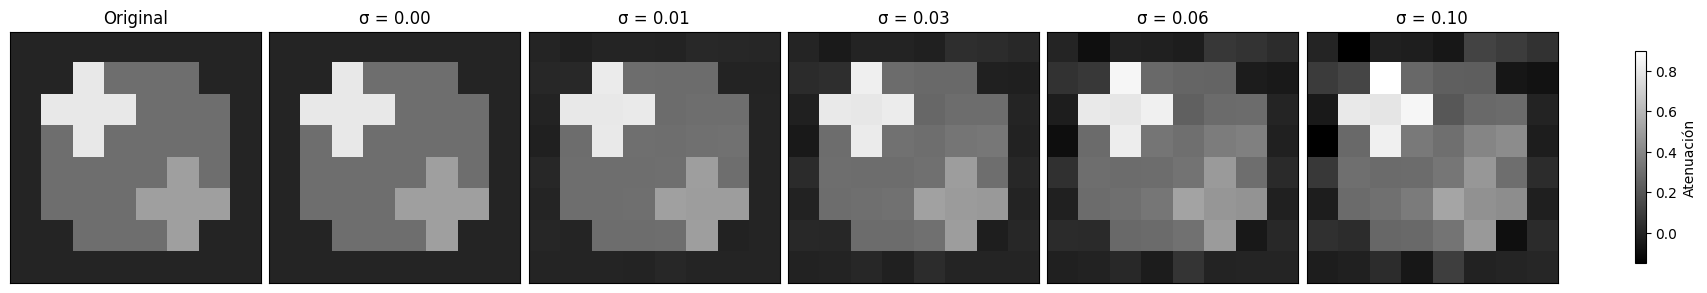

In [7]:
reconstrucciones = {}
resultados = []
print(f"{'Sigma':>6} {'Norma ruido':>14} {'Norma residuo':>15} {'Error relativo':>15} {'Mínimo':>11} {'Máximo':>11}")
for sigma in sigmas:
    b_sigma = mediciones[sigma]
    x_rec = np.linalg.lstsq(A7, b_sigma, rcond=None)[0]
    reconstrucciones[sigma] = x_rec
    ruido = np.linalg.norm(ruidos[sigma])
    residuo = np.linalg.norm(b_sigma - A7 @ x_rec)
    error = np.linalg.norm(x_rec - x_fantoma) / np.linalg.norm(x_fantoma)
    resultados.append((sigma, ruido, residuo, error, x_rec.min(), x_rec.max()))
    print(f"{sigma:6.2f} {ruido:14.6e} {residuo:15.6e} {error:15.6e} {x_rec.min():11.4f} {x_rec.max():11.4f}")

vmin = min(0.0, min(x.min() for x in reconstrucciones.values()))
vmax = max(X_fantoma.max(), max(x.max() for x in reconstrucciones.values()))
fig, axs = plt.subplots(1, 6, figsize=(17, 3), layout="constrained")
imagenes = [X_fantoma] + [reconstrucciones[s].reshape(n, n) for s in sigmas]
titulos = ["Original"] + [f"σ = {s:.2f}" for s in sigmas]
for ax, imagen, titulo in zip(axs, imagenes, titulos):
    im = ax.imshow(imagen, cmap="gray", vmin=vmin, vmax=vmax)
    ax.set_title(titulo)
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(im, ax=axs, label="Atenuación", shrink=0.75)
plt.show()
assert np.allclose(reconstrucciones[0.0], x_fantoma)

### Inciso c)

Al aumentar $\sigma$, crecen el ruido y el error de reconstrucción. En esta realización,
el error relativo pasa de aproximadamente $0{,}019$ para $\sigma=0{,}01$ a $0{,}189$
para $\sigma=0{,}10$. Al usar el mismo vector de ruido y tener rango columna completo,
la perturbación de la solución depende linealmente de $\sigma$.

Sin ruido, $b_7$ pertenece a $\operatorname{Col}(A_7)$. Al agregar ruido, en general
$b_\sigma$ queda fuera de ese subespacio y ninguna imagen reproduce todas sus componentes
exactamente. Mínimos cuadrados deja como residuo la parte que no puede explicar el modelo.

Pueden aparecer valores negativos porque `lstsq` minimiza el residuo sobre todos los vectores
de $\mathbb{R}^{64}$ y no impone atenuaciones no negativas. No recortamos esos valores:
hacerlo cambiaría la solución de mínimos cuadrados que estamos estudiando.

Asistencia utilizada: ChatGPT / Codex para completar y revisar el código, las explicaciones y las verificaciones de este notebook.